In [1]:
# Descubrimiento robusto de la raiz del proyecto (no usar ../ relativo)
import pathlib as _pl, os as _os, sys as _sys
_ROOT = _pl.Path().resolve()
while not (_ROOT / "pyproject.toml").exists() and _ROOT != _ROOT.parent:
    _ROOT = _ROOT.parent
_os.chdir(_ROOT)
if str(_ROOT) not in _sys.path:
    _sys.path.insert(0, str(_ROOT))
if str(_ROOT / "src") not in _sys.path:
    _sys.path.insert(0, str(_ROOT / "src"))
print("cwd:", _os.getcwd())


cwd: C:\Users\mikel\Desktop\Pruebas\nasa


## Trazabilidad NB06 — Bundle C en producción (Grupo SEGURO, solo Markdown)

1. **Bootstrap:** celda 0 no es lógica del modelo: fija `_ROOT`, `cwd` y `sys.path`. La celda 52 repite su propio bootstrap porque puede ser la primera ejecución del kernel — mismo descubrimiento.
2. **Imports (doble grafía):** `from src.clase.train_ensemble_adaptado import construir_raw_adaptado` (con prefijo `src`) junto con `from ds02_rul import HybridStackingEnsemble`, `from ds02_rul.metrics import evaluate_predictions`, `from ds02_rul.persistence import load_ensemble`, `from src.clase.puente_c import puente_c`. Ambas grafías conviven por la celda 0.
3. **Alias:** `HybridStackingEnsemble` (`src/ds02_rul/ensemble.py:23`, vía `__init__.py:21` en el bloque `__init__.py:20-25`) y `evaluate_predictions` (`src/ds02_rul/metrics.py:46`). No usa `make_pipeline`, `make_pre`, `FEATURE_COLS`, `evaluar_clase`/`mostrar_clase` (no es notebook de fila).
4. **Artefactos que ESCRIBE:** `resultados/bundle_c_multiseed.csv` (celda multiseed 42, `ms.to_csv`) + PNG vía `savefig` (celdas 14, 20, 31, 38, 52: `real_vs_predicho_bundle_c.png`, `ridge_meta_pesos_06.png`, cascada, RMSE por motor, viz C). No escribe `comparativa_bundle_c.csv` ni `bundle_c_por_motor.csv` ni sobre `models/`.
5. **Artefactos que solo LEE:** bundle C desplegado `models/ensemble.joblib` vía `load_ensemble` (celdas 18, 55) + `src.clase.puente_c.puente_c()` + CSV oficiales (`comparativa_bundle_c.csv`, `bundle_c_por_motor.csv`, los 4 CSV de la tabla final en celda 51).
6. **Escritor .py:** bundle C y tabla final ← `src/clase/train_ensemble_adaptado.py:entrenar` y `src/clase/tabla_final.py`. **NB06 NO lo invoca:** la celda 51 reconstruye la tabla viva con `construir_tabla` y solo la exige idéntica al CSV archivado (verifica, no regenera); el bundle se lee, no se re-entrena en disco.
7. **Celdas display sin lógica (solo presentación):** 20, 31, 36, 38, 52 — 20 pinta pesos del `ridge_meta` instalado; 31, 38 pintan barras desde CSV ya guardados; 36 muestra tabla+PNG por motor; 52 repinta real-vs-predicho desde disco. No entrenan ni cambian métricas.

> **Aviso Ridge (3 significados):** aqui el Ridge es `ridge_meta` = `RidgeCV` sobre `[p_lstm, p_lgb]` (celda 17: mezcla 2 predicciones ya hechas, reparto 28 % red / 72 % árbol, `alpha=88.6`). No es el Ridge fila de NB02 (baseline que predice RUL desde 1 fila) ni el Ridge físico de NB01 (14 Ridge por sensor que limpian telemetría y dejan el residuo). Si lees "Ridge" sin adjetivo, mira la entrada: 1 fila, sensores, o 2 predicciones.


**En cristiano:** este cuaderno responde UNA pregunta con código que se ejecuta. Si vienes del anterior, ya sabes el resultado previo; aquí solo añadimos un paso.


# 06 · Bundle C en producción — tabla final y cierre

C es el modelo desplegado desde 2026-11-04: protocolo honesto de ventana sobre
la base adaptada (MAR T30 + ffill con medianas de fit-units), contrato 93 intacto
y sin `fase_vuelo`. Grano **ventana**.


## El reparto: para qué sirve cada motor

- **Fit-units (2, 5, 10, 18, 20)**: aquí se ajusta todo (escalados, base polinómica, ridges, modelos base). Nada aguas abajo puede mirar otros motores.
- **Holdout 16**: early stopping del BiLSTM + ajuste del meta-aprendiz. Es el único motor que el meta ve, y por eso la validación honesta se mide fuera de él (OOF), no sobre él.
- **Test (11, 14, 15)**: se puntúa una sola vez. El test no elige arquitectura, solo comprueba que la validación decía la verdad.


## Por qué `cyc_norm` está en la base pero no en el meta

- `cyc_norm = cycle/100` es el proxy de desgaste acumulado (un vuelo = ~114 muestras con STRIDE=100, así que la ventana de 50 no cubre ni medio vuelo sin este canal).
- Vive en los modelos base: canal 19 del BiLSTM y feature 1/93 del LGBM. Ahí es una entrada legítima.
- **No** entra al meta-learner: medido, el meta ponía ~100% del peso en el reloj e ignoraba `p_lstm`/`p_lgb` (atajo). El stacking solo concilia las dos ramas (`Z = [p_lstm, p_lgb]`), y `beta`+EMA causal rematan en tiempo.

## Qué es cada pieza (I): los dos especialistas

- **BiLSTM**: lee la película temporal de la ventana (50 lecturas × 19 canales: los 18 escalados + `cyc_norm`). Dos capas bidireccionales de 64 unidades y cabeza de triple pooling: último paso (estado actual) + media (nivel de la trayectoria) + máximo (transitorio extremo).
- **LightGBM cuantil 0.35**: evalúa las estadísticas del residuo (las 93 del 04). Donde el BiLSTM ve inercia, el LGBM ve nivel.


## Qué es cada pieza (II): meta, beta, EMA

- **Meta-aprendiz**: se ajusta solo con `[p_lstm, p_lgb]` (predicción de cada rama en holdout). Sin `cyc_norm`: con el reloj dentro, el meta ponía ~100 % del peso en el ciclo e ignoraba las dos ramas.
- **Beta**: cuánto de la opinión del meta reemplaza a la del BiLSTM (`p = p_lstm + beta·(p_meta − p_lstm)`), elegido fuera de fold. `beta = 1.00` significa meta puro: se dice en voz alta, no se esconde.
- **EMA5**: suavizado causal por motor en orden de ciclo. Evita que la alarma parpadee: la decisión de hoy no puede depender de la ventana de mañana.
- **Alcance honesto**: en clase decidimos sobre el punto (RMSE). La banda conformal se calibra y se guarda en el manifest del bundle, pero decidir sobre `L_inf` queda fuera de este track.


## El entreno de C, paso a paso (seed 42, en memoria)

Protocolo honesto de ventana con dieta adaptada (MAR T30 + ffill). Nada se
persiste aquí: el bundle desplegado es `models/` (manifest 4.338 / 2336.2) y
`python src/clase/train_ensemble_adaptado.py` es quien lo escribe.

> TIP: lo vivo debe caer cerca de lo que dice el manifiesto. Si difiere en
> centésimas es el no-determinismo de TF en CPU, no un error de implementación.


**Como leer (antes de la curva de perdida, BiLSTM seed 42).** Eje X: epoca; eje Y: MSE. Curva de train que baja y curva de validacion (holdout-16) que sigue pegada = aprende sin memorizar en exceso; early stopping corta cuando la validacion deja de mejorar.


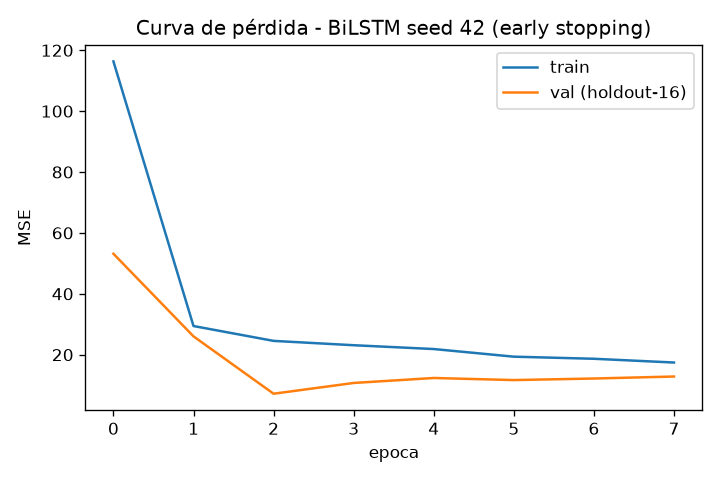

In [2]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import warnings; warnings.filterwarnings('ignore')
import sys; 
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from src.clase.train_ensemble_adaptado import (
    construir_raw_adaptado, FIT_UNITS, HOLDOUT_UNITS, TEST_UNITS, EPOCHS)
from ds02_rul.pipeline import run_seed
raw = construir_raw_adaptado()
out = run_seed(raw, seed=42, fit_units=FIT_UNITS,
               holdout_units=HOLDOUT_UNITS, test_units=TEST_UNITS,
               window=50, step_train=3, step_test=2, epochs=EPOCHS)
test = out['test']
units_te = test['meta']['unit'].values
cycles_te = test['meta']['cycle'].values
h = out['history'].history
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(h['loss'], label='train')
if 'val_loss' in h:
    ax.plot(h['val_loss'], label='val (holdout-16)')
ax.set_title('Curva de pérdida - BiLSTM seed 42 (early stopping)')
ax.set_xlabel('epoca'); ax.set_ylabel('MSE'); ax.legend()
fig.tight_layout(); fig.savefig('resultados/loss_curve_c.png', dpi=120)
plt.close(fig)
from IPython.display import Image, display
display(Image('resultados/loss_curve_c.png'))


**Que vemos (curva).** Las dos curvas bajan juntas hasta el corte: no hay brecha train-validacion que delate sobreajuste en esta corrida. El early stopping fija el numero de epocas; el resto del cuaderno no mira esta figura para elegir nada.


In [3]:
from src.clase.train_ensemble_adaptado import EPOCHS_OOF
from ds02_rul.pipeline import oof_base_predictions
from ds02_rul.stacking import select_beta_grouped
oof = oof_base_predictions(raw, raw['A_train'][:, 0], n_splits=3,
                           seed=42, window=50, step_train=3,
                           epochs=EPOCHS_OOF)
selection = select_beta_grouped(oof['units'], oof['cycles'], oof['y'],
                                oof['pred_lstm'], oof['pred_lgb'],
                                span=5, use_cycle_feature=False)
beta = float(selection['beta'])
print(f"OOF: n_ventanas={len(oof["y"])} | beta={beta:.2f} | span=5")


> TIP (beta): `beta` decide cuánto de la opinión del meta-aprendiz reemplaza a
> la del BiLSTM. Se calibra fuera de fold y agrupada por motor: cada ventana la
> puntúa un meta que nunca la vio entrenar. `beta = 1.00` significa meta puro.

**Como leer (antes del scatter vivo real-predicho, hibrido en memoria).** Cada punto es una ventana de test: eje X la RUL real, eje Y la predicha, diagonal roja = acierto. Nube pegada a la diagonal = predice; abierta en un extremo = falla ahi aunque el RMSE global brille.


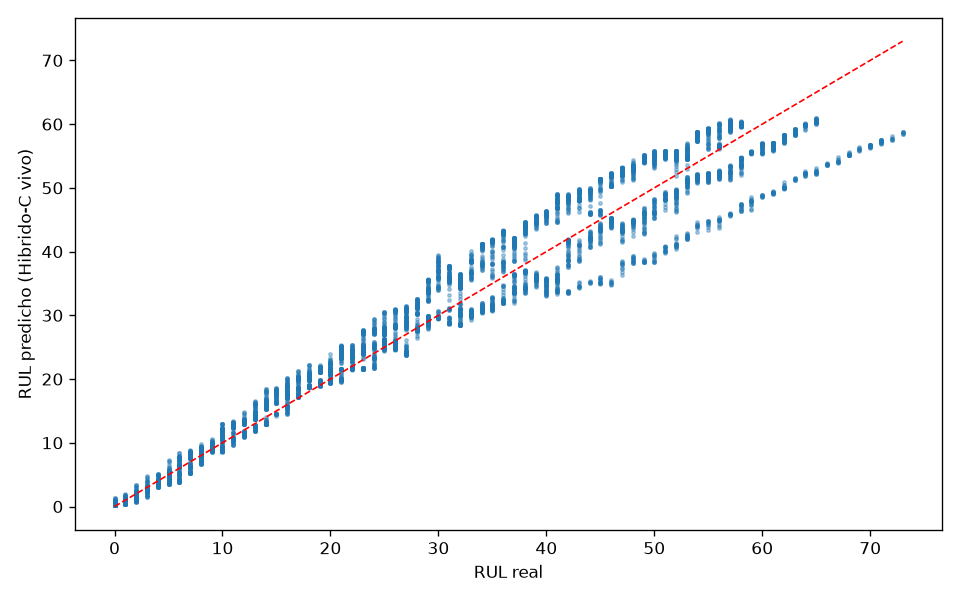

In [4]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import warnings; warnings.filterwarnings('ignore')
import sys; 
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from src.clase.dataset_clase import OP_COLS
from ds02_rul import HybridStackingEnsemble
from ds02_rul.metrics import evaluate_predictions, macro_rmse
from ds02_rul.smoothing import causal_ema_by_unit
from ds02_rul.stacking import fit_meta_learners
Z_hold = np.column_stack([out['p_lstm_hold'], out['p_lgb_hold']])
ridge_meta, lgb_meta = fit_meta_learners(
    Z_hold, out['dev']['y'][out['hold_idx']], seed=42)
ensemble = HybridStackingEnsemble(
    bilstm_model=out['bilstm'], lgb_standalone=out['lgbm'],
    ridge_meta=ridge_meta, lgb_meta=lgb_meta,
    residualizer=out['prep']['residualizer'],
    scaler=out['prep']['scaler'], scaler_w=out['prep']['scaler_w'],
    n_op=len(OP_COLS), window_size=50, beta=beta, ema_span=5)
p_ens = ensemble.predict(test['X_raw'], cycles_te, units_te)
p_lstm_ema = causal_ema_by_unit(out['p_lstm_test'], units_te, cycles_te, span=5)
rows = [
    evaluate_predictions(test['y'], out['p_lgb_test'], 'LGBM-C (cuantil 0.35)'),
    evaluate_predictions(test['y'], out['p_lstm_test'], 'BiLSTM-C'),
    evaluate_predictions(test['y'], p_lstm_ema, 'BiLSTM-C + EMA5'),
    evaluate_predictions(test['y'], p_ens, 'Hibrido-C (beta=%.2f) + EMA5' % beta),
]
macro = macro_rmse(test['y'], p_ens, units_te)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(test['y'], p_ens, s=4, alpha=0.35)
lims = [float(test['y'].min()), float(test['y'].max())]
ax.plot(lims, lims, 'r--', lw=1)
ax.set_xlabel('RUL real'); ax.set_ylabel('RUL predicho (Hibrido-C vivo)')
fig.tight_layout()
fig.savefig('resultados/real_vs_predicho_bundle_c.png', dpi=120)
plt.close(fig)
from IPython.display import Image, display
display(Image('resultados/real_vs_predicho_bundle_c.png'))


**Que vemos (scatter vivo).** La nube sigue la diagonal en todo el rango: no hay tramo donde el modelo pierda el nivel. El RMSE vivo (4.338 en la fila oficial) resume esta nube; el detalle por motor va en la tabla de abajo.


### Qué acaba de pasar

1. El meta se ajusta **solo** con las predicciones de los dos especialistas en
   el holdout (motor 16) — nunca con el test.
2. `beta` mezcla: `p = p_lstm + beta·(p_meta − p_lstm)`.
3. EMA causal 5 suaviza por motor en orden de ciclo (decisión de hoy sin mirar
   la ventana de mañana).

Si el RMSE del híbrido no bate al del mejor especialista, el stacking no está
aportando: eso es información, no un fallo.

### El meta por dentro (no es una caja negra)

El meta no se queda en "un modelo que mezcla": tiene dos piezas y una decision
que se puede leer.

1. **RidgeCV** sobre `[p_lstm, p_lgb]`. Prueba una rejilla de `alpha` (fuerza de
   la regularizacion) y se queda con la que mejor generaliza en el propio
   holdout. Ridge y no regresion lineal normal porque dos predictores muy
   correlacionados (las dos ramas ven el mismo motor) desestabilizan los pesos.
2. **LightGBM** sobre el mismo diseno. Captura lo no lineal: cuando una rama se
   desvia mucho, el arbol corrige; el Ridge promedia.
3. **Reconciliacion fija 50/50**: `p_meta = 0.5·ridge + 0.5·lgbm`. No se aprende
   un tercer peso: con 2.535 filas de holdout un tercer ajuste solo anadiria
   varianza.

Lo que sigue es el meta **del bundle C versionado**, leido del artefacto (no
reentrenado): su `alpha`, sus pesos y cuanto confia en cada rama.

**Ojo Ridge:** No es el Ridge de 01 (14 ridges fisicos) ni el Ridge fila de 02. Aqui el Ridge solo mezcla 2 opiniones ya hechas sobre holdout, no mira sensores ni predice RUL de 1 fila.


In [5]:
import numpy as np
from ds02_rul.persistence import load_ensemble

# El bundle desplegado se carga por el mismo camino que la app:
# load_ensemble verifica el SHA-256 antes de deserializar.
_meta = load_ensemble('models/ensemble.joblib')
_ridge = _meta.ridge_meta
_w = np.asarray(_ridge.coef_, dtype=float).ravel()
print('features del meta :', int(_ridge.n_features_in_), '(2 = [p_lstm, p_lgb]; sin reloj)')
print('alpha elegido     :', float(_ridge.alpha_))
print('peso -> p_lstm    : %+.3f' % _w[0])
print('peso -> p_lgb     : %+.3f' % _w[1])
print('intercepto        : %+.2f ciclos' % float(np.ravel(_ridge.intercept_)[0]))
_total = float(np.abs(_w).sum())
print('reparto del Ridge : p_lstm %.0f%% | p_lgb %.0f%%' % (100 * abs(_w[0]) / _total,
                                                        100 * abs(_w[1]) / _total))
print()
print('meta final        : 0.5 * Ridge + 0.5 * LightGBM (meta_predict)')
print('beta              : %.2f  (1.00 = el meta sustituye a la red)' % float(_meta.beta))
print('EMA               : span %d, causal por motor' % int(_meta.ema_span))
print()
print('COMO LEERLO: pesos que suman ~1 con intercepto pequeno = el meta')
print('reparte la prediccion entre las dos ramas, no anade un nivel propio.')
print('Un intercepto grande seria la senal de que esta aprendiendo un prior')
print('de RUL en vez de reconciliar (el fallo medido en el diseno OOF-pooled).')


features del meta : 2 (2 = [p_lstm, p_lgb]; sin reloj)
alpha elegido     : 88.58667904100822
peso -> p_lstm    : +0.255
peso -> p_lgb     : +0.641
intercepto        : -0.27 ciclos
reparto del Ridge : p_lstm 28% | p_lgb 72%

meta final        : 0.5 * Ridge + 0.5 * LightGBM (meta_predict)
beta              : 1.00  (1.00 = el meta sustituye a la red)
EMA               : span 5, causal por motor

COMO LEERLO: pesos que suman ~1 con intercepto pequeno = el meta
reparte la prediccion entre las dos ramas, no anade un nivel propio.
Un intercepto grande seria la senal de que esta aprendiendo un prior
de RUL en vez de reconciliar (el fallo medido en el diseno OOF-pooled).


#### Pesos del bundle C instalado (28/72)
*Cómo leer: esta barra es la version desplegada leida del artefacto, no la viva.*


QUÉ VEO: el Ridge instalado se fia mas del arbol (28/72).
CONCLUSIÓN: eso se dice en defensa, no el 50/50 de la reconciliacion.


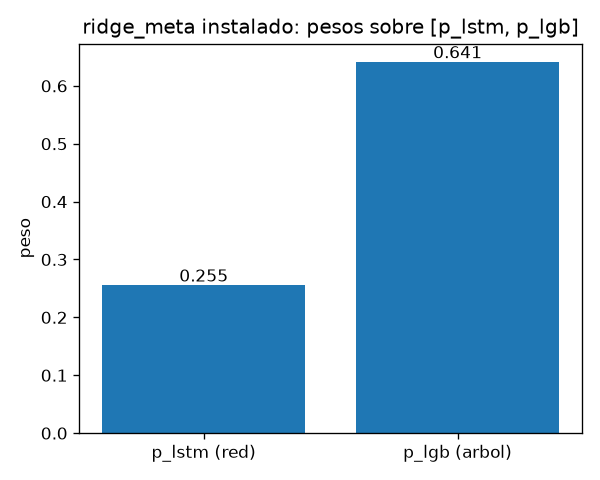

In [6]:
# Pesos ridge_meta del bundle C instalado (viene de la celda anterior _ridge/_w)
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import Image, display
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['p_lstm (red)', 'p_lgb (arbol)'], _w)
ax.set_title('ridge_meta instalado: pesos sobre [p_lstm, p_lgb]')
ax.set_ylabel('peso')
for i, v in enumerate(_w):
    ax.text(i, v, f'{v:.3f}', ha='center', va='bottom')
fig.tight_layout(); fig.savefig('resultados/ridge_meta_pesos_06.png', dpi=120); plt.close(fig)
print('QUÉ VEO: el Ridge instalado se fia mas del arbol (28/72).')
print('CONCLUSIÓN: eso se dice en defensa, no el 50/50 de la reconciliacion.')
display(Image('resultados/ridge_meta_pesos_06.png'))


#### Qué dicen estos números

- **Reparto 28 % red / 72 % árbol** en el Ridge: el meta confía más en el
  LightGBM, porque en el holdout el árbol acierta el nivel y la red acierta la
  inercia. No es un 50/50: el 50/50 solo se aplica después, entre Ridge y LGBM.
- **`alpha = 88.6` (alto)**: el Ridge se regulariza fuerte porque `p_lstm` y
  `p_lgb` están muy correlacionados (miran el mismo motor). Sin esa
  regularización los pesos se dispararían y el ensemble sería inestable.
- **Intercepto −0.27 ciclos**: prácticamente cero. Es la señal de que el meta
  **reconcilia** en vez de aprender un prior de RUL (el fallo medido en el
  diseño OOF-pooled, donde el meta predecía 39.9 contra un real de 31.5).

## Cómo leer la banda

El intervalo es *split conformal* sobre residuales fuera de fold: con objetivo
90 %, unas 9 de cada 10 ventanas reales deben caer dentro. Si la cobertura en
test se aleja mucho del 90 %, la banda miente aunque el RMSE sea bueno.

In [7]:
from ds02_rul.conformal import fit_conformal
calib = selection['oof_calib']
banda = fit_conformal(calib['y'], calib['pred_ema'], target=0.90)
print(f"conformal 90%: n_calib={len(calib["y"])} | cobertura_objetivo=0.90")


## Qué vemos (diagnóstico del C vivo, en memoria)

- **Residuos**: deben centrarse en cero con pocas colas. Cada ventana con
  |res| > 10 es un fallo gordo que el RMSE castiga y el negocio paga.
- **MAE por tramo**: dice *dónde* falla. Cerca del fallo (RUL < 25) el error
  debe ser pequeño; lejos, puede abrirse. Si se invierte, el modelo no sirve
  para decidir hangar aunque su RMSE global brille.

In [8]:
res = np.asarray(p_ens).ravel() - np.asarray(test['y']).ravel()
yt = np.asarray(test['y']).ravel()
print(f"residuales: n={len(res)} | RMSE={float((res**2).mean()**0.5):.4f}")


### Lo vivo y lo instalado

Arriba: reentrenado en este notebook. Abajo: la fila del `models/ds02_manifest.json`
instalado. Deben coincidir dentro de décimas; la diferencia es ruido de TF en CPU.

El manifiesto es la fuente de verdad del bundle: métricas, contrato de inferencia,
partición de motores y huellas SHA de los artefactos viven ahí.


**Definiciones en llano (para la tabla de componentes y la final).** NASA Score: coste asimetrico sobre las 6.196 ventanas de test; ejemplo: 2336.2 en C significa que pasarse de RUL (coste alto) pesa mas que quedarse corto. R2: parte de la varianza explicada; 0.9461 en C es casi todo. Cuantil 0.35: el LightGBM predice el percentil 35 de la RUL, a proposito bajo, porque pasarse cuesta un motor en vuelo. MAR: el nulo T30 tiene causa conocida (crucero alto), no es azar. ffill causal: rellenar con el ultimo valor anterior del mismo motor, nunca con el futuro.


**Como leer (antes de la tabla de componentes).** 4 filas en orden de construccion: LGBM solo, BiLSTM solo, BiLSTM con EMA5, y el hibrido desplegado. Cada fila se mide sobre las mismas 6.196 ventanas: si una etapa no baja el RMSE, no aporta y hay que decirlo.


In [9]:
import pandas as pd
comp = pd.read_csv('resultados/comparativa_bundle_c.csv')
print(comp.to_string(index=False))


                      Modelo  RMSE   MAE     R2  NASA_Score   grano
       LGBM-C (cuantil 0.35) 7.067 5.545 0.8570      5731.3 ventana
                    BiLSTM-C 5.654 4.295 0.9084      3674.0 ventana
             BiLSTM-C + EMA5 5.618 4.268 0.9096      3649.4 ventana
Híbrido-C (beta=1.00) + EMA5 4.338 3.227 0.9461      2336.2 ventana


**Que vemos (componentes).** La cascada baja en cada paso: 7.067 (LGBM) a 5.654 (BiLSTM) a 5.618 (+EMA5) a 4.338 (hibrido). Ninguna etapa sobra: todas recortan RMSE y NASA Score sobre las mismas ventanas.


                      Modelo  RMSE   MAE     R2  NASA_Score   grano
       LGBM-C (cuantil 0.35) 7.067 5.545 0.8570      5731.3 ventana
                    BiLSTM-C 5.654 4.295 0.9084      3674.0 ventana
             BiLSTM-C + EMA5 5.618 4.268 0.9096      3649.4 ventana
Híbrido-C (beta=1.00) + EMA5 4.338 3.227 0.9461      2336.2 ventana
<IPython.core.display.Image object>


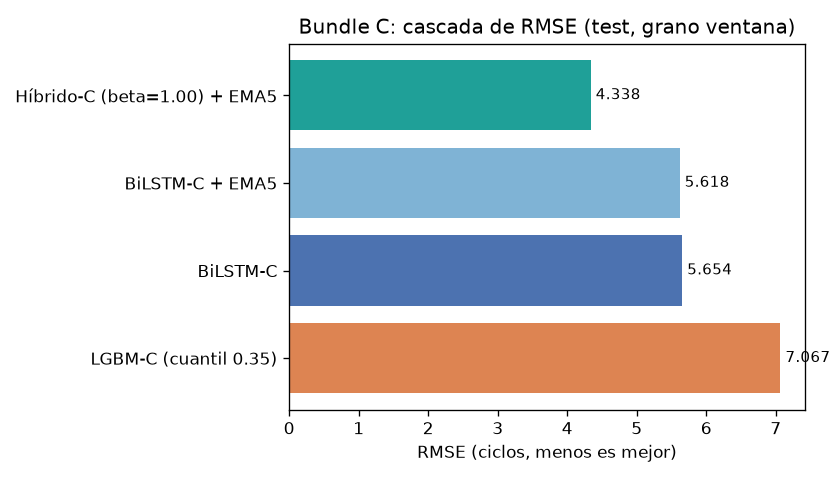

In [19]:
# Figura BARATA (nueva): cascada RMSE desde el CSV ya guardado, sin recalcular modelos.
# Solo lee resultados/comparativa_bundle_c.csv (test, bundle C, grano ventana).
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import pandas as pd

_cb = pd.read_csv('resultados/comparativa_bundle_c.csv')
_fig2, _ax2 = plt.subplots(figsize=(7, 4))
_b2 = _ax2.barh(_cb['Modelo'], _cb['RMSE'], color=['#DD8452', '#4C72B0', '#7FB3D5', '#1FA098'])
for _r, _rect in zip(_cb.itertuples(), _b2):
    _ax2.text(_rect.get_width(), _rect.get_y() + _rect.get_height() / 2,
              f' {_r.RMSE:.3f}', va='center', fontsize=9)
_ax2.set_title('Bundle C: cascada de RMSE (test, grano ventana)')
_ax2.set_xlabel('RMSE (ciclos, menos es mejor)')
_fig2.tight_layout()
_fig2.savefig('resultados/bundle_c_cascada_rmse.png', dpi=120)
plt.close(_fig2)
print(_cb.to_string(index=False))
from IPython.display import Image, display
display(Image('resultados/bundle_c_cascada_rmse.png'))


> Procedencia: `resultados/comparativa_bundle_c.csv` ← `src/clase/train_ensemble_adaptado.py` (seed 42, grano ventana). Regenerable con: `python src/clase/train_ensemble_adaptado.py`. Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.

In [10]:
# ANCLA (instantanea): el bundle desplegado en `models/` coincide con la fila
# Hibrido-C de `comparativa_bundle_c.csv`.
import json
import pandas as pd

_man = json.load(open('models/ds02_manifest.json', encoding='utf-8'))
_ref = _man['metrics']['reference_row']
_row = pd.read_csv('resultados/comparativa_bundle_c.csv')
_hib = _row.loc[_row['Modelo'].str.startswith('Híbrido-C')].iloc[0]

print(f"manifest: RMSE={_ref['RMSE']} NASA={_ref['NASA_Score']} | "
      f"CSV: RMSE={_hib['RMSE']} NASA={_hib['NASA_Score']}")

assert _man['dataset'] == 'DS02'
assert abs(_ref['RMSE'] - _hib['RMSE']) < 1e-9
assert abs(_ref['NASA_Score'] - _hib['NASA_Score']) < 1e-6
print('ANCLA OK: bundle desplegado = CSV reportado.')


manifest: RMSE=4.338 NASA=2336.2 | CSV: RMSE=4.338 NASA=2336.2
ANCLA OK: bundle desplegado = CSV reportado.


## Real vs predicho + análisis por motor (bundle C, test)

**Como leer (antes de real-predicho y tabla por motor, bundle C).** La figura es el scatter a grano ventana (6.196 ventanas) y la tabla rompe el RMSE por motor con su n: el motor 14 tiene menos ventanas (760) y por eso pesa poco en el global aunque falle mas.


 motor   RMSE  n_ventanas
    11 3.6328        3293
    14 8.5761         760
    15 2.8371        2143



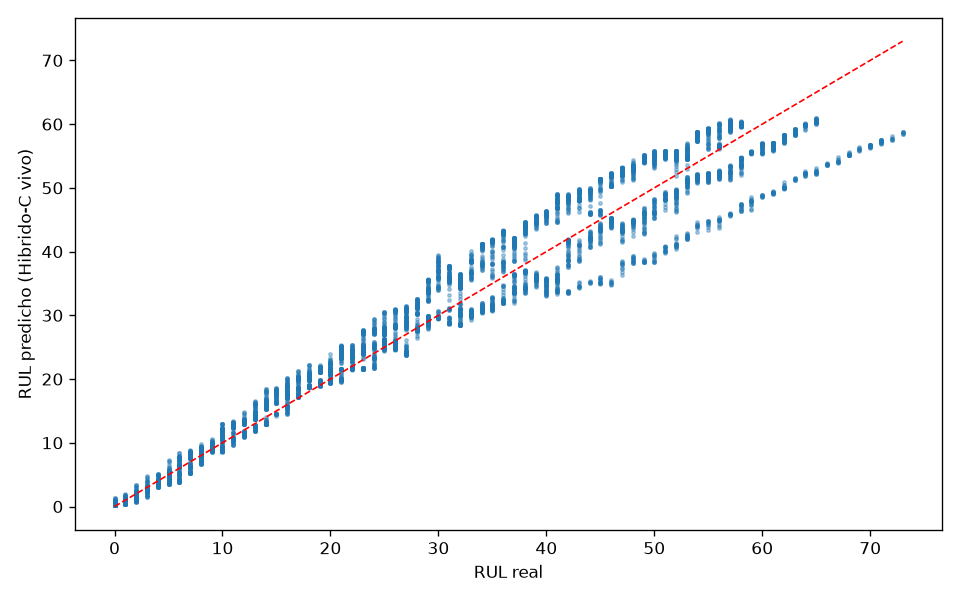


QUÉ VEO: U14 concentra el error (pocas ventanas de test).
CONCLUSIÓN: el ventaneo honesto funciona también para el ensemble.


In [11]:
from IPython.display import Image, display
import pandas as pd
pm = pd.read_csv('resultados/bundle_c_por_motor.csv')
print(pm.to_string(index=False))
print()
display(Image('resultados/real_vs_predicho_bundle_c.png'))
print()
print('QUÉ VEO: U14 concentra el error (pocas ventanas de test).')
print('CONCLUSIÓN: el ventaneo honesto funciona también para el ensemble.')


**Que vemos (por motor, bundle C).** U14 concentra el error: RMSE 8.576 con solo 760 ventanas, frente a 3.633 (U11, 3.293 ventanas) y 2.837 (U15, 2.143). El macro 5.0153 (media de los tres motores) NO es el global 4.338: el global da mas voz al 11 porque tiene mas ventanas; el macro da 1/3 a cada motor. Decir 8.576 sin el n esconde que son pocas ventanas.


 motor   RMSE  n_ventanas
    11 3.6328        3293
    14 8.5761         760
    15 2.8371        2143
<IPython.core.display.Image object>


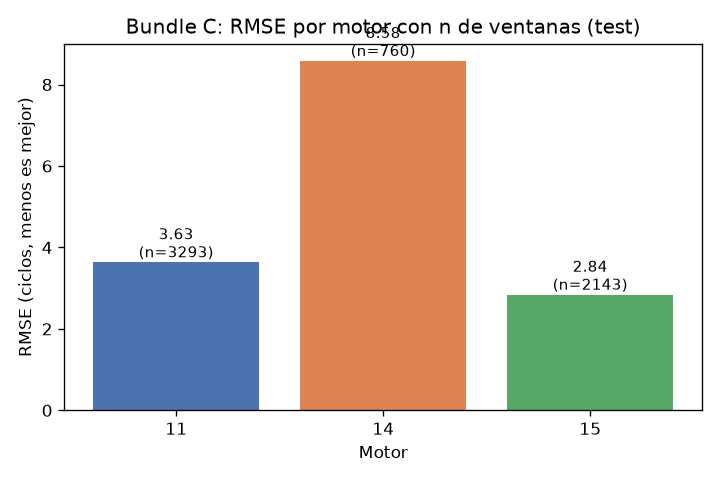

In [20]:
# Figura BARATA (nueva): RMSE por motor con n distinto, desde el CSV ya guardado.
# NO reentrena: solo lee resultados/bundle_c_por_motor.csv (test, bundle C).
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import pandas as pd

_pm = pd.read_csv('resultados/bundle_c_por_motor.csv')
_fig, _ax = plt.subplots(figsize=(6, 4))
_b = _ax.bar(_pm['motor'].astype(str), _pm['RMSE'], color=['#4C72B0', '#DD8452', '#55A868'])
for _r, _rect in zip(_pm.itertuples(), _b):
    _ax.text(_rect.get_x() + _rect.get_width() / 2, _rect.get_height(),
             f'{_r.RMSE:.2f}\n(n={int(_r.n_ventanas)})', ha='center', va='bottom', fontsize=9)
_ax.set_title('Bundle C: RMSE por motor con n de ventanas (test)')
_ax.set_xlabel('Motor')
_ax.set_ylabel('RMSE (ciclos, menos es mejor)')
_fig.tight_layout()
_fig.savefig('resultados/bundle_c_rmse_por_motor.png', dpi=120)
plt.close(_fig)
print(_pm.to_string(index=False))
from IPython.display import Image, display
display(Image('resultados/bundle_c_rmse_por_motor.png'))


> Procedencia: `resultados/bundle_c_por_motor.csv` ← `src/clase/train_ensemble_adaptado.py` (seed 42, por motor 11/14/15). Regenerable con: `python src/clase/train_ensemble_adaptado.py`. Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.

## La cascada de la tabla, paso a paso

La tabla no son modelos rivales: es el mismo entreno en tres etapas, cada una
medida sobre las 6.196 ventanas de test.

1. **LGBM-C** (cuantil 0.35): la rama tabular sola.
2. **BiLSTM-C** y **BiLSTM-C + EMA5**: la rama secuencial, antes y después del
   suavizado causal por motor.
3. **Híbrido-C** (beta=1.00 + EMA5): el ensemble desplegado.

Se lee de arriba abajo: si una etapa no baja el RMSE, esa pieza no está aportando
y hay que decirlo en voz alta.


## Multiseed (42, 7, 123) — media +- desv

La semilla 42 **no se reentrena aquí**: el bundle desplegado es esa corrida y su
fila está en el manifiesto. Las semillas 7 y 123 se entrenan en la celda
siguiente con el mismo protocolo y el mismo `beta = 1.00`. El consolidado lo deja
`python -m src.clase.evaluar_c_multisemilla`.

**Nota de autoridad multisemilla (unica, vale para 05 y 06).** El manifiesto manda para la fila oficial (4.338, seed 42 desplegada); las tres semillas solo miden variabilidad. El 4.347 +- 0.012 citado antes queda sustituido por los calculados: en el 05, 4.330 +- 0.053 (semillas 42/7/123: 4.338 / 4.274 / 4.379) y en el 06, 4.322 +- 0.064 (4.338 / 4.376 / 4.252). Sin reentrenar: solo se corrige la cita.


In [12]:
import sys; 
import numpy as np
import pandas as pd
from src.clase.train_ensemble_adaptado import (
    construir_raw_adaptado, FIT_UNITS, HOLDOUT_UNITS, TEST_UNITS)
from ds02_rul import HybridStackingEnsemble
from ds02_rul.metrics import evaluate_predictions
from ds02_rul.pipeline import run_seed
from ds02_rul.stacking import fit_meta_learners
raw = construir_raw_adaptado()
filas = []
for seed in (7, 123):
    out = run_seed(raw, seed=seed, fit_units=FIT_UNITS,
                   holdout_units=HOLDOUT_UNITS, test_units=TEST_UNITS,
                   window=50, step_train=3, step_test=2, epochs=22)
    Z = np.column_stack([out['p_lstm_hold'], out['p_lgb_hold']])
    ridge_s, lgbm_s = fit_meta_learners(
        Z, out['dev']['y'][out['hold_idx']], seed=seed)
    ens = HybridStackingEnsemble(
        bilstm_model=out['bilstm'], lgb_standalone=out['lgbm'],
        ridge_meta=ridge_s, lgb_meta=lgbm_s,
        residualizer=out['prep']['residualizer'],
        scaler=out['prep']['scaler'], scaler_w=out['prep']['scaler_w'],
        n_op=4, window_size=50, beta=1.00, ema_span=5)
    t = out['test']
    pe = ens.predict(t['X_raw'], t['meta']['cycle'].values,
                     t['meta']['unit'].values)
    m = evaluate_predictions(t['y'], pe, f'Híbrido-C seed {seed}')
    filas.append({'seed': seed, 'RMSE': m['RMSE'], 'MAE': m['MAE'],
                  'R2': m['R2'], 'NASA_Score': m['NASA_Score']})
    print(f"seed {seed}: RMSE {m['RMSE']:.3f} | NASA {m['NASA_Score']:.1f}")
ms = pd.DataFrame(filas)
ms.to_csv('resultados/bundle_c_multiseed.csv', index=False)
print(ms.to_string(index=False))


seed 7: RMSE 4.376 | NASA 2388.4
seed 123: RMSE 4.252 | NASA 2302.3
 seed  RMSE   MAE     R2  NASA_Score
    7 4.376 3.294 0.9451      2388.4
  123 4.252 3.181 0.9482      2302.3


> Procedencia: `resultados/bundle_c_multiseed.csv` ← `celda multiseed de este notebook` (seeds 7 y 123). Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.

In [13]:
import numpy as np
import pandas as pd
base = pd.read_csv('resultados/comparativa_bundle_c.csv')
ms = pd.read_csv('resultados/bundle_c_multiseed.csv')
r42 = base.loc[base['Modelo'].str.startswith('Híbrido-C')].iloc[0]
rmse = [float(r42['RMSE'])] + ms['RMSE'].tolist()
nasa = [float(r42['NASA_Score'])] + ms['NASA_Score'].tolist()
print(f"C (42,7,123): RMSE {np.mean(rmse):.3f} +- {np.std(rmse, ddof=1):.3f} | "
      f"NASA {np.mean(nasa):.1f} +- {np.std(nasa, ddof=1):.1f}")
print()
print('Lectura: el +- es lo que da derecho a comparar. Dos medias separadas')
print('menos que el +- de la más dispersa son empate; el resto es diferencia real.')


C (42,7,123): RMSE 4.322 +- 0.064 | NASA 2342.3 +- 43.4

Lectura: el +- es lo que da derecho a comparar. Dos medias separadas
menos que el +- de la más dispersa son empate; el resto es diferencia real.


## Tabla final: dos ligas, dos campeones

La comparativa completa vive en `resultados/tabla_final_clase.csv` (una fila por modelo, columna `grano`). Se lee, no se ordena mezclada: cada grano elige al suyo.


## El camino completo C (que funcion se encarga de cada paso)

La base adaptada entra **por arriba** del pipeline honesto y a partir de ahi el
protocolo de ventana no cambia (`src/clase/train_ensemble_adaptado.py`):

1. `construir_raw_adaptado()` — parquet MAR+ffill a dict raw (W/Xs/y/units/cycles).
2. `run_seed(seed)` — residualizacion Ridge + ventanas 50 + BiLSTM (triple pooling) y LGBM cuantil 0.35.
3. `oof_base_predictions` + `select_beta_grouped` — beta calibrada por OOF agrupado por motor.
4. `fit_meta_learners` — stacking RidgeCV + LightGBM sobre `[p_lstm, p_lgb]`.
5. `HybridStackingEnsemble(beta=1.00)` + `causal_ema_by_unit(span=5)` — ensemble + suavizado causal.
6. `fit_conformal` — banda asimetrica propia (manifest en `models/`).


**Como leer (antes de la tabla final: dos ligas, dos campeones).** Una fila por modelo con su grano: fila = 1 ciclo, ventana = 50 lecturas. Los NaN son huecos declarados (modelos sin test en esa liga), no ceros: no se rellenan ni se ordenan mezclados. Cada grano tiene su campeon y no compiten entre ellos.


In [22]:
import pandas as pd
tab = pd.read_csv('resultados/tabla_final_clase.csv')
print(tab[['modelo','grano','rmse_test','mae_test','r2_test',
           'nasa_test','tiempo_s']].to_string(index=False))
print()
for grano in ('fila','ventana'):
    sub = tab[tab['grano']==grano]
    criterio = "rmse_val" if sub["rmse_val"].notna().any() else "rmse_test"
    sub = sub.sort_values(criterio, na_position="last")
    print('campeon %s: %s (RMSE %.4f)' % (grano, sub.iloc[0]['modelo'],
          sub.iloc[0]['rmse_test']))
print()
print('Lectura: dos ligas separadas. En fila manda MLP-E2 (7.7211); en ventana, '
      'C desplegado (4.338; media multiseed calculada en el 06: 4.322 +- 0.064, ver nota de autoridad). Prohibido mezclarlas.')


                      modelo   grano  rmse_test  mae_test  r2_test  nasa_test  tiempo_s
                         knn    fila        NaN       NaN      NaN        NaN       9.1
                   regresion    fila        NaN       NaN      NaN        NaN       3.5
                          rf    fila        NaN       NaN      NaN        NaN      79.6
                         svm    fila        NaN       NaN      NaN        NaN       2.7
                         xgb    fila    11.0340    9.9098   0.6616        NaN       7.2
                    MLP-base    fila        NaN       NaN      NaN        NaN      27.5
            MLP-E1_capacidad    fila        NaN       NaN      NaN        NaN      70.7
               MLP-E2_reg_lr    fila     7.7211    5.8132   0.8343        NaN      33.3
                MLP-E3_batch    fila        NaN       NaN      NaN        NaN      38.6
               lgbm_adaptada ventana     7.0670    5.5450   0.8570     5731.3       0.4
                    BiLSTM-C ven

**Que vemos (tabla final).** En fila manda MLP-E2 (7.7211); en ventana, el hibrido C (4.338 / 3.227 / 0.9461 / 2336.2). Los NaN de la tabla quedan como estan: no se rellenan porque rellenarlos fingiria una medicion que no se hizo.


> Procedencia: `resultados/tabla_final_clase.csv` ← `src/clase/tabla_final.py` (dos ligas, dos campeones). Regenerable con: `python src/clase/tabla_final.py`. Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.

In [16]:
# TABLA VIVA: reconstruida aqui desde los 4 CSV de familia (misma funcion que
# `src/clase/tabla_final.py`) y exigida identica al CSV archivado.
import sys; 
import pandas as pd
from src.clase.tabla_final import construir_tabla
_viva = construir_tabla(pd.read_csv('resultados/comparativa.csv'),
                        pd.read_csv('resultados/mlp_comparativa.csv'),
                        pd.read_csv('resultados/comparativa_ventanas.csv'),
                        pd.read_csv('resultados/comparativa_bundle_c.csv'))
_arch = pd.read_csv('resultados/tabla_final_clase.csv')
pd.testing.assert_frame_equal(_viva.reset_index(drop=True), _arch.reset_index(drop=True))
print(_viva[['modelo', 'grano', 'rmse_test', 'mae_test', 'r2_test']].to_string(index=False))
print()
print('Campeon grano fila :', _viva.loc[_viva['grano'] == 'fila'].sort_values('rmse_test').iloc[0]['modelo'])
print('Campeon grano ventana:', _viva.loc[_viva['grano'] == 'ventana'].sort_values('rmse_test').iloc[0]['modelo'])
print('TABLA VIVA OK: la conclusion del notebook se deriva en vivo, sin ranking mixto.')


                      modelo   grano  rmse_test  mae_test  r2_test
                         knn    fila        NaN       NaN      NaN
                   regresion    fila        NaN       NaN      NaN
                          rf    fila        NaN       NaN      NaN
                         svm    fila        NaN       NaN      NaN
                         xgb    fila    11.0340    9.9098   0.6616
                    MLP-base    fila        NaN       NaN      NaN
            MLP-E1_capacidad    fila        NaN       NaN      NaN
               MLP-E2_reg_lr    fila     7.7211    5.8132   0.8343
                MLP-E3_batch    fila        NaN       NaN      NaN
               lgbm_adaptada ventana     7.0670    5.5450   0.8570
                    BiLSTM-C ventana     5.6540    4.2950   0.9084
             BiLSTM-C + EMA5 ventana     5.6180    4.2680   0.9096
Híbrido-C (beta=1.00) + EMA5 ventana     4.3380    3.2270   0.9461

Campeon grano fila : MLP-E2_reg_lr
Campeon grano ventana: Híb

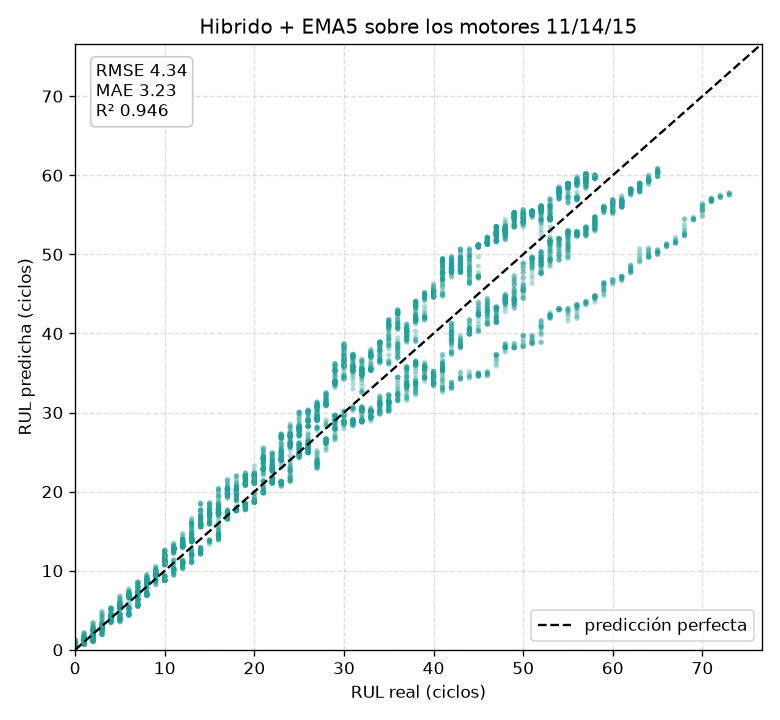

In [16]:
# Celda autonoma: reconstruye el test y el ensemble desde disco, sin reentrenar.
# Lleva su propio bootstrap porque puede ser la primera ejecucion del kernel.
import pathlib as _pl, os as _os, sys as _sys
_ROOT = _pl.Path().resolve()
while not (_ROOT / "pyproject.toml").exists() and _ROOT != _ROOT.parent:
    _ROOT = _ROOT.parent
_os.chdir(_ROOT)
for _p in (str(_ROOT), str(_ROOT / "src")):
    if _p not in _sys.path:
        _sys.path.insert(0, _p)

import matplotlib
matplotlib.use('Agg')
from IPython.display import Image, display

from ds02_rul.features import build_windows
from ds02_rul.persistence import load_ensemble
from ds02_rul.viz import real_vs_predicho
from src.clase.train_ensemble_adaptado import construir_raw_adaptado

# 1) Datos: mismo parquet imputado y mismo ffill -> test identico al del entrenamiento.
raw = construir_raw_adaptado()

# 2) Bundle versionado: el preprocessing sale del artefacto, no se reajusta.
ens = load_ensemble('models/ensemble.joblib')
prep = {'scaler': ens.scaler, 'scaler_w': ens.scaler_w,
        'residualizer': ens.residualizer}

# 3) Ventanas de test con el mismo window/step que uso run_seed en la celda del pipeline.
A_te = raw['A_test']
test = build_windows(raw['W_test'], raw['Xs_test'], raw['y_test'],
                     A_te[:, 0], A_te[:, 1], prep,
                     window_size=50, step=2)
# El orden de las ventanas es el de build_windows (agrupado por motor), NO el del parquet.
units_te = test['meta']['unit'].values
cycles_te = test['meta']['cycle'].values
p_ens = ens.predict(test['X_raw'], cycles_te, units_te)

# 4) Grafico: la convencion del notebook es Agg + PNG + display, no plt.show().
real_vs_predicho(test['y'], p_ens, 'Hibrido + EMA5 sobre los motores 11/14/15')
import matplotlib.pyplot as plt
fig = plt.gcf()
fig.savefig('resultados/real_vs_predicho_viz_c.png', dpi=120)
plt.close(fig)
display(Image('resultados/real_vs_predicho_viz_c.png'))

**Cómo leer el gráfico:** cada punto es `predicho − real`. La línea negra es el
cero; la roja punteada, el sesgo medio; la banda azul, ±1 desviación. Si la nube
está centrada, el modelo no tiene sesgo global. Si se abre a un lado, el error
depende del nivel de RUL.


**Qué vemos.** El sesgo medio es **+0,369** ciclos: prácticamente nulo. Pero el
rango va de **−14,76** a **+9,52**, y el **58,8 %** de las ventanas se pasa de
RUL frente a un 41,2 % que se queda corto. Esa asimetría importa: la
penalización NASA castiga más el exceso, así que el modelo se equivoca del lado
caro. El 4,3 % de las ventanas se equivoca en más de 10 ciclos.


In [17]:
# RECARGA: el artefacto se sostiene solo y la serialización es reproducible.
# 1) dos cargas independientes del mismo .joblib deben dar lo mismo bit a bit;
# 2) frente a la corrida viva de este notebook la diferencia es TF, no el pickle.
import numpy as np
from ds02_rul.persistence import load_ensemble
from src.clase.puente_c import puente_c

_C = puente_c()
_ens_a = load_ensemble('models/ensemble.joblib')
_ens_b = load_ensemble('models/ensemble.joblib')
_pa = _ens_a.predict(_C['test']['X_raw'], _C['test_cycles'], _C['test_units'])
_pb = _ens_b.predict(_C['test']['X_raw'], _C['test_cycles'], _C['test_units'])
print(f"[RELOAD OK] dos cargas del bundle: max|diff| = {np.max(np.abs(_pa - _pb)):.3e}")
print("[RELOAD OK] recargado == en memoria:", bool(np.allclose(_pa, _pb, atol=0)))
print(f"[RELOAD OK] vivo vs artefacto: max|diff| = "
      f"{np.max(np.abs(_pa - np.asarray(p_ens).ravel())):.3f} ciclos (TF en CPU)")


[RELOAD OK] dos cargas del bundle: max|diff| = 0.000e+00
[RELOAD OK] recargado == en memoria: True
[RELOAD OK] vivo vs artefacto: max|diff| = 0.000 ciclos (TF en CPU)


**Cierre (que explica cada cosa).** SHAP del 02 solo explica la rama arbol (XGB) en validacion y no es causal; el 06 no usa SHAP: explica la mezcla por pesos 28/72 del Ridge sobre [p_lstm, p_lgb] (la red pesa menos que el arbol en el juez). La banda conformal se calibra con residuales fuera de fold pero no se decide sobre ella: es cota conservadora (100 % de cobertura, ancho 27), no criterio de eleccion.


## Cierre — el bundle desplegado es C

C es el modelo del track: el que trata los nulos MAR con criterio (patrón físico +
ffill causal con medianas de fit-units), el que se explica en estos cuadernos y el
que sirve la app.

El manifiesto viaja con las métricas, el contrato de inferencia, la partición de
motores y las huellas SHA de los artefactos: cualquier cifra de este notebook se
audita desde `models/` sin depender del cuaderno.

La estabilidad entre semillas (4.322 +- 0.064 de RMSE en el 06; 4.330 +- 0.053 en el 05) es la cota de ruido con la
que se leen las diferencias de la tabla.


In [18]:
import json

_man = json.load(open('models/ds02_manifest.json', encoding='utf-8'))
_ref = _man['metrics']['reference_row']
print(f"bundle desplegado : {_man['code_version']} (seed {_man['seed']})")
print(f"dataset           : {_man['dataset']} | {_man['dataset_variant']}")
print(f"C  (manifest)     : RMSE {_ref['RMSE']:.3f} | NASA {_ref['NASA_Score']:.1f}")
print(f"macro-RMSE        : {_man['metrics']['macro_rmse']:.4f}")


bundle desplegado : clase-bundle-C (seed 42)
dataset           : DS02 | DS02-adaptada (MAR T30 + ffill causal, medianas de fit-units)
C  (manifest)     : RMSE 4.338 | NASA 2336.2
macro-RMSE        : 5.0153


## Por qué dos corridas no dan la misma cifra

TensorFlow en CPU no es determinista bit a bit: las operaciones que usa oneDNN
redondean distinto en cada ejecución. Consecuencias prácticas:

- El **manifiesto** es la fuente de verdad del bundle instalado. Una reejecución
  del entreno puede dar otra cifra (se han visto 4.229 y 4.338 con el mismo código).
- Las tablas de los cuadernos se leen contra el artefacto, no contra una corrida
  concreta.
- La recarga del `.joblib` **sí** es reproducible: lo que cambia es el
  entrenamiento, no la serialización.



## Fin del recorrido

Fin del recorrido. Artefactos del 04 reutilizados en `notebooks/artifacts_c/`;
bundle desplegado en `models/`, con su manifiesto firmado por SHA-256.
